# La pinza: forma de la mordaza, geometría y verificación

**Taller de Proyecto I (E0306) — 2.º cuatrimestre 2026 — Grupo N.º 3**

---

## Alcance

En el cuaderno de dimensionamiento resolví la pinza en media página: calculé el par por
fuerza de agarre, 0,72 kg·cm, con un brazo de palanca de 30 mm **supuesto**. No había
geometría, ni forma de mordaza, ni verificación de que el conjunto entre donde tiene que
entrar. Este cuaderno cierra eso y corrige dos errores de aquel cálculo.

Responde cuatro preguntas:

1. Qué forma de mordaza conviene: plana, en V, o siguiendo la geometría del vaso.
2. Qué mecanismo y con qué dimensiones.
3. Si el par, la masa y el volumen verifican contra lo que el informe ya tiene escrito.
4. Qué le toca al firmware.

Los datos de entrada vienen de otros cuadernos y no se vuelven a discutir: el recipiente de
**145 g** y Ø55 mm interior, el **MG996R** con 9,52 kg·cm a 4,89 V, el presupuesto de
**90 g para la pinza completa con su servo** y los **85 mm** del eje de la muñeca a la punta
de los dedos. Todo usa solo `math`.

---

# 1. Qué hay que agarrar

| Dato | Valor | De dónde sale |
|---|---|---|
| Diámetro interior | 55 mm | cuaderno de dimensionamiento |
| Pared del vaso | 1 mm | **adoptado**; se confirma con calibre al comprar el vaso |
| **Diámetro exterior nominal** | **57 mm** | es el que ve la pinza |
| Altura | 90 mm | |
| Nivel de agua | 44 mm | |
| Masa llena | 145 g | límite, no valor nominal |
| Conicidad | 2,2° de semiángulo | **adoptada**, de 50 mm en la base a 57 en la boca |
| Rozamiento μ | 0,30 | valor conservador, plástico liso sobre plástico liso |

El recipiente definitivo es una **decisión pendiente** registrada en la Tabla 9 del informe.
Eso no es un detalle administrativo sino un requisito de diseño: **la pinza no puede quedar
atada a un diámetro**. Dimensiono para 57 mm y verifico el rango que tolera sin tocar nada.

---

# 2. Qué forma de mordaza

Las tres formas se comparan por lo mismo: **cuánta normal total consiguen por cada newton
que el dedo empuja hacia el eje**. La fricción disponible y el par que resiste el giro son
los dos proporcionales a esa normal total, así que una sola cifra ordena las opciones.

- **Plana**: una línea de contacto, la normal total es la fuerza del dedo.
- **En V** de semiángulo $\beta$: dos caras inclinadas, $F = 2N\,\mathrm{sen}\,\beta$, de
  donde la normal total vale $F/\mathrm{sen}\,\beta$.
- **Conformada**, abrazando $\pm\alpha$: la presión se reparte sobre el arco y las
  componentes radiales se cancelan en parte. Proyectando, $F = 2pRL\,\mathrm{sen}\,\alpha$,
  mientras que la normal total es $2pRL\,\alpha$: el cociente es
  $\alpha/\mathrm{sen}\,\alpha$.

In [1]:
import math

print(f"{'mordaza':<34}{'normal total / F':>18}")
print('-' * 52)
print(f"{'plana':<34}{1.00:>18.2f}")
for inc in (90, 105, 120, 135):
    print(f"{'en V de ' + str(inc) + ' grados':<34}"
          f"{1/math.sin(math.radians(inc/2)):>18.2f}")
print('-' * 52)
for arco in (30, 45, 60, 75, 90):
    a = math.radians(arco)
    print(f"{'conformada, abraza +-' + str(arco) + ' grados':<34}"
          f"{a/math.sin(a):>18.2f}")

mordaza                             normal total / F
----------------------------------------------------
plana                                           1.00
en V de 90 grados                               1.41
en V de 105 grados                              1.26
en V de 120 grados                              1.15
en V de 135 grados                              1.08
----------------------------------------------------
conformada, abraza +-30 grados                  1.05
conformada, abraza +-45 grados                  1.11
conformada, abraza +-60 grados                  1.21
conformada, abraza +-75 grados                  1.36
conformada, abraza +-90 grados                  1.57


**La V le gana a la conformada.** Una mordaza que copie el vaso y lo abrace ±60° consigue
1,21; una V de 90°, con dos caras planas, consigue 1,41. Leyendo la tabla al revés, la
conformada recién empata a la V de 90° abrazando algo más de ±75°, o sea más de 150° por
dedo y 300° entre los dos: imposible, los dedos no tendrían por dónde soltar el vaso.

La conformada tiene una ventaja real, repartir la presión en vez de concentrarla en una
línea. Resulta que no hace falta: la sección 6 muestra que la presión de contacto es de
**0,007 MPa**, tres órdenes de magnitud por debajo de lo que deforma una pared de plástico.
El problema que la conformada resuelve, acá no existe.

Y tiene dos costos que sí pesan: **se ata a un diámetro** —hay que reimprimirla para
cualquier otro vaso, mientras que la V toma un rango y además autocentra— y **se ata a una
conicidad**.

> **Conclusión.** Mordaza en V. Pero conviene no exagerar lo que la forma aporta: entre una
> plana y una V razonable hay un factor de 1,15 a 1,4. Pegar una **pastilla de TPU**, que
> sube μ de 0,30 a 0,60, aporta un factor de **2**. La forma de la mordaza es de segundo
> orden; el rozamiento es de primero.

---

# 3. El mecanismo

Dos dedos que giran sobre ejes verticales paralelos, acoplados por un par de **sectores
dentados 1:1**, con el servo moviendo uno solo.

Los sectores no son un lujo: hacen que los dos dedos se muevan en espejo, y eso es lo que
**autocentra** el vaso. Con un solo dedo móvil el vaso se correría hacia el dedo fijo al
cerrar, y el brazo tendría que acercarse con una precisión que no tiene.

Cada dedo es un brazo que sale del pivote y termina en el vértice de una V, con la
bisectriz **perpendicular al brazo**. Esa perpendicularidad da el máximo brazo de palanca
posible: si la bisectriz apuntara al pivote, la fuerza pasaría por el eje de giro y el dedo
no haría ninguna fuerza. Con esa disposición el **brazo de palanca es igual al largo del
dedo** y no depende del ángulo de giro, lo que reemplaza el supuesto de 30 mm por un número
que sale del dibujo.

---

# 4. La geometría

El vaso se apoya en las dos caras de cada V, así que su eje queda sobre la bisectriz, a
$d = r/\mathrm{sen}\,\beta$ del vértice. Pidiendo que ese eje caiga sobre la línea media
queda una sola ecuación con una sola incógnita, el giro del dedo:

$$P = L_f\,\mathrm{sen}\,t + d\,\cos t
\qquad\Longrightarrow\qquad
t = \arcsin\frac{P}{\sqrt{L_f^2 + d^2}} - \arctan\frac{d}{L_f}$$

con $P$ la media separación entre pivotes y $L_f$ el largo del dedo. No hace falta iterar.

La geometría no la elige el par —sobra por todos lados— sino **cuatro restricciones
geométricas**, que fui encontrando al dibujar:

1. **El vaso tiene que quedar delante del plano de pivotes.** Si no, se mete entre los
   pivotes y choca con el soporte del servo. Fue la última que agregué y la que cambió el
   resultado.
2. **Los dos dedos no se pueden tocar** con el vaso más chico del rango.
3. **El servo tiene que entrar** entre el eje de la muñeca y el plano de pivotes.
4. **La pinza tiene que soltar**, no solo agarrar.

La cuarta obliga a una sutileza de modelado. Si se trata a las caras de la V como rectas
infinitas, la cara trasera pasa cerca del eje del vaso para cualquier giro y el criterio
dice que la pinza **nunca** suelta, que es falso: la cara es un segmento de 21 mm y termina
antes. Por eso la distancia se mide al segmento y no a la recta.

Probé sacar esta cuarta restricción del barrido para simplificarlo, y no se puede: es la que
ata la geometría. Sin ella el barrido elige pinzas más chicas que después no sueltan.

In [2]:
G, M_CARGA, MU, FS = 9.81, 0.145, 0.30, 2.0
D_MIN, D_NOM, D_MAX = 50.0, 57.0, 65.0     # ventana de vaso, diametros exteriores
SERVO, L3 = 45.0, 85.0                     # hueco del MG996R, y el largo disponible

def dedo(P, LF, beta, D):
    '''Giro del dedo, vertice de la V, bisectriz y eje del vaso. None si no llega.'''
    d = D/2/math.sin(beta)
    R = math.hypot(LF, d)
    if P > R:
        return None
    t = math.asin(P/R) - math.atan2(d, LF)
    V = (P - LF*math.sin(t), LF*math.cos(t))
    g = math.atan2(-math.sin(t), -math.cos(t))
    return t, V, g, (V[0] + d*math.cos(g), V[1] + d*math.sin(g))

def caras(V, g, beta, LC):
    '''Los dos segmentos que forman la V, desde el vertice.'''
    return [(V, (V[0] + LC*math.cos(g + s*beta), V[1] + LC*math.sin(g + s*beta)))
            for s in (+1, -1)]

def dist_segmento(C, A, B):
    ax, ay = B[0] - A[0], B[1] - A[1]
    s = max(0.0, min(1.0, ((C[0]-A[0])*ax + (C[1]-A[1])*ay)/(ax*ax + ay*ay)))
    return math.hypot(C[0] - (A[0] + s*ax), C[1] - (A[1] + s*ay))

def giro_para_soltar(P, LF, beta, LC, D):
    '''Cuanto tiene que girar el dedo, desde agarrado, hasta despegarse 3 mm.'''
    t_ini, _, _, C = dedo(P, LF, beta, D)
    t = t_ini
    while t > math.radians(-80):
        V = (P - LF*math.sin(t), LF*math.cos(t))
        g = math.atan2(-math.sin(t), -math.cos(t))
        if min(dist_segmento(C, A, B) for A, B in caras(V, g, beta, LC)) >= D/2 + 3:
            return t_ini - t
        t -= math.radians(0.25)
    return None

def cumple(P, LF, beta):
    '''Las cuatro restricciones. Devuelve el caso o None.'''
    LC = D_MAX/2/math.tan(beta) + 2            # cara recortada al contacto
    for D in (D_MIN, D_NOM, D_MAX):
        s = dedo(P, LF, beta, D)
        if s is None or s[3][1] - D/2 < 3:     # 1) el vaso, delante
            return None
    cy = dedo(P, LF, beta, D_NOM)[3][1]
    if L3 - cy < SERVO:                        # 3) entra el servo
        return None
    _, V, g, _ = dedo(P, LF, beta, D_MIN)
    luz = min([V[0]] + [B[0] for _, B in caras(V, g, beta, LC)])
    if luz < 3:                                # 2) los dedos no se tocan
        return None
    rec = giro_para_soltar(P, LF, beta, LC, D_MAX)
    if rec is None:                            # 4) suelta
        return None
    F = M_CARGA*G*math.sin(beta)/(2*MU)
    return dict(P=P, LF=LF, LC=LC, cy=cy, luz=luz, F=F,
                rec=math.degrees(rec), kg=2*F*LF/1000*100/G)

print(f"{'V incl':>7}{'ampl':>6}{'2p':>6}{'dedo':>6}{'cara':>6}{'eje vaso':>10}"
      f"{'delante':>9}{'al servo':>10}{'luz':>7}{'recorrido':>11}"
      f"{'F/dedo':>8}{'par xFS2':>10}{'margen':>8}")
print('-' * 112)
for inc in (80, 90, 100, 110, 120):
    beta = math.radians(inc/2)
    hallado = None
    for LF10 in range(180, 501, 5):
        for p2 in range(40, 101):
            hallado = cumple(p2/2, LF10/10, beta)
            if hallado:
                break
        if hallado:
            break
    if hallado is None:
        print(f"{inc:>4} deg   sin solucion")
        continue
    r = hallado
    print(f"{inc:>4} deg{1/math.sin(beta):>6.2f}{2*r['P']:>6.0f}{r['LF']:>6.0f}"
          f"{r['LC']:>5.0f}m{r['cy']:>9.1f}m{r['cy']-D_NOM/2:>7.1f}m"
          f"{L3-r['cy']:>8.0f}mm{r['luz']:>6.1f}m{r['rec']:>10.0f}deg"
          f"{r['F']:>7.2f}N{r['kg']*FS:>9.2f}{(9.52/(r['kg']*FS)-1)*100:>7.0f}%")

 V incl  ampl    2p  dedo  cara  eje vaso  delante  al servo    luz  recorrido  F/dedo  par xFS2  margen
----------------------------------------------------------------------------------------------------------------
  80 deg  1.56    75    28   41m     36.3m    7.8m      49mm   6.4m        59deg   1.52N     1.71    457%
  90 deg  1.41    68    26   35m     34.2m    5.7m      51mm   9.7m        59deg   1.68N     1.81    426%


 100 deg  1.31    58    26   29m     34.5m    6.0m      50mm  10.8m        56deg   1.82N     1.89    404%
 110 deg  1.22    52    24   25m     33.0m    4.5m      52mm  12.6m        54deg   1.94N     1.86    412%
 120 deg  1.15    45    22   21m     32.2m    3.7m      53mm  13.3m        51deg   2.05N     1.80    429%


Las cinco cumplen, así que **el par no decide**: el margen pasa del 400 % en todas. Lo que
decide es tamaño y masa. La V de 80° necesita pivotes a 69 mm y caras de 41 mm; la de 120°,
pivotes a 45 mm y caras de 21 mm. Los dedos de la V ancha pesan un 40 % menos, y esa masa
cuelga a 28 cm del hombro, que es la articulación más exigida del brazo.

La amplificación que se pierde —de 1,56 a 1,15— no compra nada: el margen de par ya sobra y
la presión de contacto es despreciable en todos los casos.

**Adopto la V de 120°:** 45 mm entre pivotes, dedo de 22 mm, cara de 21 mm.

---

# 5. La geometría adoptada

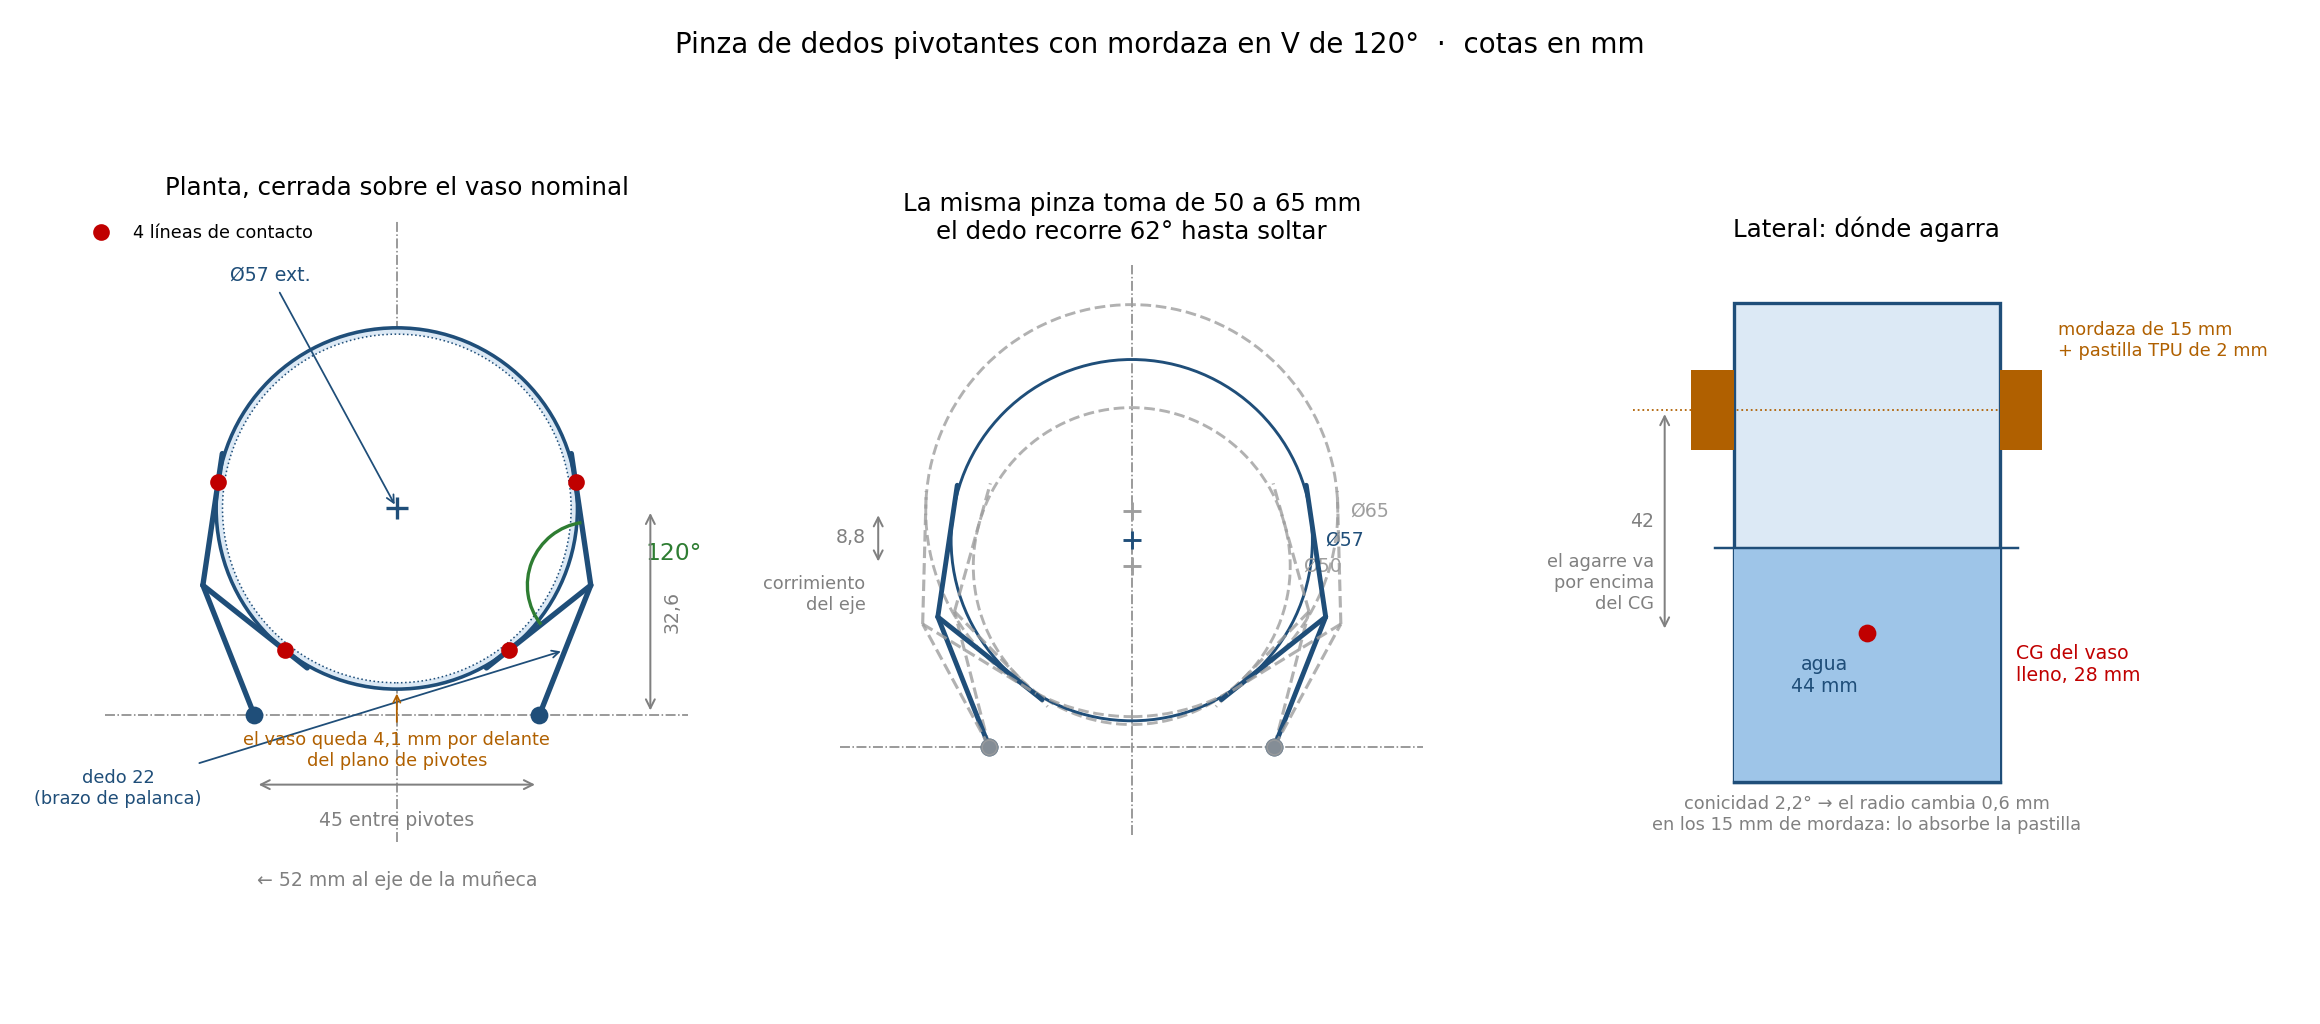

**Figura 1.** Pinza de dedos pivotantes con mordaza en V de 120°. Cotas en mm.

In [3]:
INC, P, LF = 120.0, 22.5, 22.0
BETA = math.radians(INC/2)
LCARA = D_MAX/2/math.tan(BETA) + 2

print(f"V de {INC:.0f} grados, pivotes a {2*P:.0f} mm, dedo {LF:.0f} mm, "
      f"cara {LCARA:.0f} mm\n")
print(f"{'vaso':>6}{'giro':>8}{'vertice-eje':>14}{'eje del vaso':>15}"
      f"{'contacto':>11}{'delante':>10}")
print('-' * 64)
cys = []
for D in (D_MIN, D_NOM, D_MAX):
    t, V, g, C = dedo(P, LF, BETA, D)
    cys.append(C[1])
    print(f"{D:>4.0f}mm{math.degrees(t):>7.0f}d{D/2/math.sin(BETA):>12.1f}mm"
          f"{C[1]:>13.1f}mm{D/2/math.tan(BETA):>9.1f}mm{C[1]-D/2:>8.1f}mm")

desv = max(abs(cys[0]-cys[1]), abs(cys[2]-cys[1]))
print(f"\nel eje del vaso se corre {max(cys)-min(cys):.1f} mm en todo el rango "
      f"({cys[0]-cys[1]:+.1f} / {cys[2]-cys[1]:+.1f} respecto del nominal)")
print(f"eso cambia el momento del hombro en {M_CARGA*desv/10:.2f} kg.cm de 11,96, "
      f"un {M_CARGA*desv/10/11.96*100:.1f} %")
print(f"del eje de la muneca al plano de pivotes: {L3-cys[1]:.0f} mm, "
      f"y el MG996R mide 40,7")
t_chico = dedo(P, LF, BETA, D_MIN)[0]
t_suelta = dedo(P, LF, BETA, D_MAX)[0] - giro_para_soltar(P, LF, BETA, LCARA, D_MAX)
print()
print(f"del vaso grande agarrado a soltarlo    : "
      f"{giro_para_soltar(P, LF, BETA, LCARA, D_MAX)*180/math.pi:.0f} grados")
print(f"recorrido total que usa el servo      : "
      f"{math.degrees(t_chico - t_suelta):.0f} grados de 180, "
      f"del vaso chico agarrado al grande suelto")

V de 120 grados, pivotes a 45 mm, dedo 22 mm, cara 21 mm

  vaso    giro   vertice-eje   eje del vaso   contacto   delante
----------------------------------------------------------------
  50mm    -14d        28.9mm         28.5mm     14.4mm     3.5mm
  57mm    -22d        32.9mm         32.6mm     16.5mm     4.1mm
  65mm    -28d        37.5mm         37.2mm     18.8mm     4.7mm

el eje del vaso se corre 8.8 mm en todo el rango (-4.1 / +4.7 respecto del nominal)
eso cambia el momento del hombro en 0.07 kg.cm de 11,96, un 0.6 %
del eje de la muneca al plano de pivotes: 52 mm, y el MG996R mide 40,7

del vaso grande agarrado a soltarlo    : 48 grados
recorrido total que usa el servo      : 62 grados de 180, del vaso chico agarrado al grande suelto


El corrimiento del eje con el diámetro es la contrapartida de que la pinza sea tolerante:
un vaso más grande se apoya más adelante. Nueve milímetros sobre 325 cambian el momento del
hombro un 0,6 %, que se pierde dentro del factor de seguridad.

Fuera de la ventana de 50 a 65 mm la pinza sigue agarrando, pero el corrimiento empieza a
notarse. **Al comprar el vaso conviene quedarse entre 52 y 63 mm**, que es donde el eje no
se mueve más de 5 mm respecto del nominal.

---

# 6. Fuerza, par y presión

El vaso se sostiene por rozamiento en las cuatro líneas de contacto. Para que no deslice,
$4\mu N \ge mg$, y como por dedo $F = 2N\,\mathrm{sen}\,\beta$:

$$F = \frac{m\,g\,\mathrm{sen}\,\beta}{2\,\mu}$$

El servo mueve **los dos dedos** a través de los sectores, así que entrega el doble del par
de uno. El cuaderno anterior calculaba el par de un solo dedo: ese factor 2 faltaba.

La pastilla de TPU se dimensiona por el recorrido del punto de contacto, que se corre con el
diámetro del vaso.

In [4]:
F = M_CARGA*G*math.sin(BETA)/(2*MU)
N = F/(2*math.sin(BETA))
kg = 2*F*LF/1000*100/G

recorrido_contacto = D_MAX/2/math.tan(BETA) - D_MIN/2/math.tan(BETA)
LARGO_PAST, ALTO_MORD = 12.0, 15.0          # mm; el largo cubre ese recorrido
A_PAST = LARGO_PAST*ALTO_MORD

print(f"resultante por dedo              : {F:.2f} N")
print(f"normal por cara (son cuatro)     : {N:.2f} N")
print(f"friccion disponible              : {4*MU*N:.2f} N contra "
      f"{M_CARGA*G:.2f} N de peso")
print(f"par en el servo, los dos dedos   : {kg:.2f} kg.cm")
print(f"x FS {FS:.0f}                            : {kg*FS:.2f} kg.cm de 9,52   "
      f"margen {(9.52/(kg*FS)-1)*100:.0f} %")
print(f"\nel contacto se corre {recorrido_contacto:.1f} mm sobre la cara entre "
      f"los dos extremos del rango,")
print(f"asi que la pastilla de {LARGO_PAST:.0f} x {ALTO_MORD:.0f} mm lo cubre "
      f"con margen ({A_PAST:.0f} mm2)\n")

F_max = 9.52*G/100/(2*LF/1000)
print(f"{'condicion':<24}{'F/dedo':>10}{'N/cara':>10}{'presion':>12}")
print('-' * 56)
for nombre, f_ in (("lo necesario", F), ("con FS 2", 2*F),
                   ("el servo a pleno par", F_max)):
    print(f"{nombre:<24}{f_:>7.2f} N{f_/(2*math.sin(BETA)):>7.2f} N"
          f"{f_/(2*math.sin(BETA))/A_PAST:>8.3f} MPa")
print(f"\nel servo puede apretar {F_max/F:.0f} veces mas de lo necesario")

resultante por dedo              : 2.05 N
normal por cara (son cuatro)     : 1.19 N
friccion disponible              : 1.42 N contra 1.42 N de peso
par en el servo, los dos dedos   : 0.92 kg.cm
x FS 2                            : 1.84 kg.cm de 9,52   margen 417 %

el contacto se corre 4.3 mm sobre la cara entre los dos extremos del rango,
asi que la pastilla de 12 x 15 mm lo cubre con margen (180 mm2)

condicion                   F/dedo    N/cara     presion
--------------------------------------------------------
lo necesario               2.05 N   1.19 N   0.007 MPa
con FS 2                   4.11 N   2.37 N   0.013 MPa
el servo a pleno par      21.23 N  12.25 N   0.068 MPa

el servo puede apretar 10 veces mas de lo necesario


Dos lecturas.

**La presión no es un problema.** Con la pastilla, en el peor caso previsto es de 0,013 MPa.
Por eso la mordaza conformada no hacía falta.

**El riesgo es el opuesto al que esperaba.** El servo puede apretar diez veces más de lo
necesario: la pinza no corre riesgo de que se le caiga el vaso, corre riesgo de
**aplastarlo**. El límite no lo puede poner el par disponible, lo tiene que poner el
firmware con un tope de ángulo de cierre calibrado contra el vaso definitivo. La pastilla de
TPU ayuda porque es elástica y convierte ese tope de ángulo en una fuerza acotada.

---

# 7. El giro del vaso

El requerimiento 3.1.3 pide que el vaso no gire durante el traslado. **Ninguna forma de
mordaza da bloqueo de forma** contra el giro alrededor del eje del vaso, porque todos los
contactos quedan sobre la circunferencia: lo único que lo impide es el rozamiento. Lo que
hay que verificar es si alcanza.

El par a transmitir sale del giro de la base: el vaso tiene que acelerar angularmente con
ella. Lo tomo como cilindro macizo, que sobrestima la inercia —el agua no se pone a girar de
inmediato— y por lo tanto queda del lado seguro.

In [5]:
r = D_NOM/2/1000
J = 0.5*M_CARGA*r**2
ALFA = 3.02                               # rad/s2, del cuaderno de dimensionamiento

print(f"inercia del vaso lleno sobre su eje : {J:.2e} kg.m2")
print(f"par a transmitir                    : {J*ALFA*1000:.3f} mN.m")
print(f"par que resiste el agarre           : {4*MU*N*r*1000:.0f} mN.m")
print(f"margen                              : x{4*MU*N*r/(J*ALFA):.0f}")

inercia del vaso lleno sobre su eje : 5.89e-05 kg.m2
par a transmitir                    : 0.178 mN.m
par que resiste el agarre           : 41 mN.m
margen                              : x228


Doscientas veces. El requerimiento queda cubierto por rozamiento, sin ninguna forma
especial. La holgura viene de que el vaso es liviano y gira despacio, porque la velocidad
angular de la base ya está limitada por el agua.

---

# 8. Masa y volumen

Dos presupuestos que el cuaderno de dimensionamiento ya había gastado sin verificar: los
**90 g de la pinza completa** —que incluyen los 55 g del servo, o sea 35 g de estructura— y
los **85 mm** del eje de la muñeca a la punta.

Para que la masa no sea una estimación a ojo, cada dimensión sale de algo:

- **Sector dentado**: engranan en el punto medio entre pivotes, así que el radio primitivo
  es la media separación. Con el mismo módulo de 1,5 mm que los engranajes del brazo, eso
  fija los dientes. El ancho se verifica con el mismo criterio de Lewis.
- **Dedo**: el espesor no lo fija la tensión sino la rigidez y la impresión, y eso se
  comprueba calculando la tensión de flexión.
- **Eje**: alto de mordaza más espesor del soporte más arandela y tope.
- **Soporte**: la huella del servo y la separación de pivotes.

In [6]:
RHO, INFILL, ESP, MOD, LEWIS = 1270.0, 0.45, 6.0, 1.5, 0.32

z = round(2*P/MOD)
Ft = F*LF/P                                   # fuerza tangencial en el sector
ANCHO_SEC = 6.0
sigma_sec = Ft/(ANCHO_SEC*MOD*LEWIS)
sigma_dedo = (F*LF)/(ALTO_MORD*ESP**2/6)
print(f"sector: radio primitivo {P:.1f} mm, modulo {MOD} -> z = {z} dientes")
print(f"        Ft = {Ft:.2f} N, ancho {ANCHO_SEC:.0f} mm -> "
      f"{sigma_sec:.2f} MPa de 15 admisibles")
print(f"dedo:   espesor {ESP:.0f} mm -> {sigma_dedo:.2f} MPa de 15; "
      f"lo dimensiona la impresion, no la tension\n")

r_ext = (z + 2)*MOD/2
LARGO_EJE = ALTO_MORD + 3 + 4
dedos     = 2*((LF + 2*LCARA)*ESP*ALTO_MORD)*1e-9*RHO*INFILL*1000
sectores  = 2*(math.pi*r_ext**2*(70/360)*ANCHO_SEC)*1e-9*RHO*INFILL*1000
soporte   = ((2*P + 10)*45*3 + 2*45*22*3)*1e-9*RHO*INFILL*1000
ejes      = 2*(math.pi*2**2*LARGO_EJE)*1e-9*7850*1000
pastillas = 4*(LARGO_PAST*ALTO_MORD*2)*1e-9*1200*1000

for nombre, m in (("dos dedos con su V", dedos), ("dos sectores dentados", sectores),
                  ("soporte del servo", soporte), ("dos ejes de acero M4", ejes),
                  ("cuatro pastillas de TPU", pastillas)):
    print(f"  {nombre:<26}{m:>6.1f} g")
tot = dedos + sectores + soporte + ejes + pastillas
print(f"  {'TOTAL estructura':<26}{tot:>6.1f} g   de 35 g  ({35-tot:+.1f})")
print(f"  {'PINZA COMPLETA con servo':<26}{tot+55:>6.1f} g   de 90 g  "
      f"({90-tot-55:+.1f})")

sector: radio primitivo 22.5 mm, modulo 1.5 -> z = 30 dientes
        Ft = 2.01 N, ancho 6 mm -> 0.70 MPa de 15 admisibles
dedo:   espesor 6 mm -> 0.50 MPa de 15; lo dimensiona la impresion, no la tension

  dos dedos con su V           6.5 g
  dos sectores dentados        2.4 g
  soporte del servo            7.6 g
  dos ejes de acero M4         4.3 g
  cuatro pastillas de TPU      1.7 g
  TOTAL estructura            22.7 g   de 35 g  (+12.3)
  PINZA COMPLETA con servo    77.7 g   de 90 g  (+12.3)


Entra con holgura. No hace falta tocar el cálculo del brazo: los 90 g y los 85 mm que usa
el cuaderno de dimensionamiento siguen valiendo, ahora respaldados por una geometría y no
por una estimación. Conservo los 90 g como presupuesto en vez de bajarlos al valor
calculado, porque las piezas todavía no se imprimieron y es el lado seguro.

---

# 9. Lo que el firmware tiene que respetar

| Requerimiento | Valor | Por qué |
|---|---|---|
| Tope de ángulo de cierre | a calibrar con el vaso definitivo | el servo puede apretar 10 veces de más y abollar la pared |
| Recorrido útil del servo | 62° de los 180° | del vaso chico agarrado al grande suelto, con sectores 1:1 |
| Posición de reposo | pinza abierta | si arranca cerrada, el primer movimiento es contra el vaso |
| La pinza es de dos estados | abierta / cerrada | la comanda un pulsador, no un eje analógico |

El tercero no estaba identificado antes y es el que puede romper algo en el primer encendido.

---

# 10. Lo que falta medir

1. **El rozamiento real** entre la pastilla y el vaso definitivo. Es el número del que todo
   depende y el único que adopté de tabla. Se mide inclinando una pastilla con el vaso
   apoyado hasta que desliza: μ es la tangente del ángulo.
2. **La deformación de la pared** al cerrar. Define el tope de ángulo que va al firmware.
3. **El diámetro y la conicidad** del vaso que se compre, para confirmar que cae en la
   ventana de 50 a 65 mm.
4. **El juego de los sectores dentados**, que se suma al de la transmisión de la muñeca.
5. **Pesar los dedos impresos**, igual que con los engranajes del brazo.
6. **Verificar la interferencia en tres dimensiones** al modelar: este cuaderno resuelve la
   planta, no el volumen.

Con la primera y la segunda la pinza deja de apoyarse en supuestos. Las constantes están en
las secciones 1 y 4: cambiarlas y volver a ejecutar recalcula el resto.